# Hasil Eksperimen: Hybrid Retrieval BM25 + Multilingual-E5

Notebook ini menjalankan sistem pencarian kami dan menampilkan hasilnya langkah demi langkah:
data, prapemrosesan, contoh pencarian, evaluasi pada 480 kueri TEST, uji statistik, sensitivitas, dan kecepatan.

Indeks sudah dibangun sebelumnya dengan `build_index.py`, jadi notebook ini **tidak melatih ulang apa pun**.

In [1]:
import sys, json, time
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from hybrid.data import load_queries, load_qrels, DocStore
from hybrid.preprocess import BM25Analyzer, CachedStemmer, load_stopwords
from hybrid.searcher import HybridSearcher
from hybrid.fusion import fuse
from hybrid.metrics import evaluate_run
from hybrid.stats import paired_bootstrap_ci, paired_randomization

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 80)
DATA, INDEX, OUT = ROOT / "data/miracl-id", ROOT / "indexes/miracl-id", ROOT / "outputs"

## 1. Data: MIRACL bahasa Indonesia

In [2]:
queries = load_queries(DATA / "queries_dev.tsv")
qrels = load_qrels(DATA / "qrels_dev.tsv")
split = json.load(open(OUT / "query_split.json"))
docids = json.load(open(INDEX / "docids.json"))

print(f"Jumlah dokumen (paragraf) : {len(docids):,}")
print(f"Jumlah kueri dev          : {len(queries)}")
print(f"Kueri TUNE / TEST         : {len(split['tune'])} / {len(split['test'])}")

pd.DataFrame([{"qid": q, "kueri": queries[q], "jumlah dokumen relevan": sum(r > 0 for r in qrels[q].values())}
              for q in split["test"][:5]])

Jumlah dokumen (paragraf) : 1,446,315
Jumlah kueri dev          : 960
Kueri TUNE / TEST         : 480 / 480


,qid,kueri,jumlah dokumen relevan
0,1002,berapakah luas Sulawesi Selatan ?,1
1,1024,Apa arti kata Vergangenheitsbewältigung ?,1
2,1031,Apakah definisi dari geografi ?,9
3,1038,kapankah Romusha terjadi di indonesia?,3
4,1041,Apa itu Acta Sanctorum?,1


In [3]:
store = DocStore(INDEX / "docstore.sqlite")
contoh = store.get([docids.index("4468#2")])
pd.DataFrame(contoh.values())

,docid,title,text
0,4468#2,Mesir,Dengan luas wilayah sekitar 997.739 km² Mesir mencakup Semenanjung Sinai (di...


## 2. Prapemrosesan teks (jalur BM25)

In [4]:
sw = load_stopwords()
tanpa_stem, dengan_stem = BM25Analyzer(sw), BM25Analyzer(sw, CachedStemmer())
print("Jumlah stopword:", len(sw))
for k in ["Berapa luas Mesir?", "Kapan handphone pertama diciptakan?", "Pada tahun berapa presiden Soeharto dilengserkan?"]:
    print(f"{k!r:55} -> tanpa stem: {tanpa_stem(k)} | stem: {dengan_stem(k)}")

Jumlah stopword:

 809
'Berapa luas Mesir?'                                    -> tanpa stem: ['luas', 'mesir'] | stem: ['luas', 'mesir']
'Kapan handphone pertama diciptakan?'                   -> tanpa stem: ['handphone', 'diciptakan'] | stem: ['handphone', 'cipta']
'Pada tahun berapa presiden Soeharto dilengserkan?'     -> tanpa stem: ['tahun', 'presiden', 'soeharto', 'dilengserkan'] | stem: ['tahun', 'presiden', 'soeharto', 'lengser']


## 3. Memuat indeks BM25 dan E5 (sekali saja)

In [5]:
t = time.time()
searcher = HybridSearcher(INDEX)
print(f"Selesai dalam {time.time() - t:.1f} detik | perangkat E5: {searcher.encoder.device}")

Selesai dalam 56.5 detik | perangkat E5: cuda


## 4. Contoh pencarian

Kolom **relevan** diambil dari kunci jawaban (qrels) MIRACL.

In [6]:
def cari(kueri, mode, stem=True, alpha=0.5, rrf_k=10, top_k=5):
    qid = next((q for q, t in queries.items() if t == kueri), None)
    out = searcher.search(kueri, mode=mode, stem=stem, alpha=alpha, rrf_k=rrf_k, K=100, top_k=top_k)
    docs = store.get([r["idx"] for r in out["results"]])
    rows = []
    for r in out["results"]:
        d = docs[r["idx"]]
        rows.append({"peringkat": r["rank"], "judul": d["title"], "teks": d["text"][:70] + "...",
                     "skor": r["score"], "peringkat BM25": r["bm25_rank"] or "-", "peringkat Dense": r["dense_rank"] or "-",
                     "relevan": "✔" if qid and qrels[qid].get(r["docid"], 0) > 0 else ""})
    print(f"Kueri: {kueri} | mode: {mode} | waktu: " + ", ".join(f"{k} {v:.0f} ms" for k, v in out["timings"].items()))
    return pd.DataFrame(rows).set_index("peringkat")

KUERI = "Berapa luas Mesir?"
cari(KUERI, "bm25")

Kueri: Berapa luas Mesir? | mode: bm25 | waktu: bm25_ms 32 ms, fusion_ms 0 ms


,judul,teks,skor,peringkat BM25,peringkat Dense,relevan
peringkat,,,,,,
1,Sejarah Mesir Kuno,Besar kemungkinan sebagai akibat dari penjajahan bangsa Hyksos selama ...,11.4509,1,-,
2,Mesir Kuno,"Sementara itu, di Mesir Selatan, peradaban Naqada, mirip dengan Badari...",10.8255,2,-,
3,Abdurrahman Mohammad Fachir,"Di bidang sosial budaya, Pusat Kebudayaan dan Informasi Indonesia (PUS...",10.8009,3,-,
4,Agama Mesir Kuno,"Meskipun bangsa Mesir tidak memiliki kitab keagamaan yang terpadu, mer...",10.7264,4,-,
5,Militer Mesir kuno,Gurun yang luas di daerah Mesir menjadi penghalang yang melindungi lem...,10.6538,5,-,


In [7]:
cari(KUERI, "dense")

Kueri: Berapa luas Mesir? | mode: dense | waktu: dense_ms 1928 ms, fusion_ms 0 ms


,judul,teks,skor,peringkat BM25,peringkat Dense,relevan
peringkat,,,,,,
1,Mesir,Dengan luas wilayah sekitar 997.739 km² Mesir mencakup Semenanjung Sin...,0.9154,-,1,✔
2,Mesir,"Mesir terletak antara garis lintang 22 ° dan 32 ° N, dan garis bujur 2...",0.8977,-,2,✔
3,Mesir,Mayoritas penduduk Mesir menetap di pinggir Sungai Nil (sekitar 40.000...,0.8561,-,3,
4,Mesir,"Terlepas dari Lembah Nil, mayoritas lanskap Mesir adalah gurun, dengan...",0.8500,-,4,
5,Mesir,"Mesir (), nama resmi Republik Arab Mesir (, ) adalah sebuah negara yan...",0.8370,-,5,


In [8]:
cari(KUERI, "linear")

Kueri: Berapa luas Mesir? | mode: linear | waktu: bm25_ms 23 ms, dense_ms 73 ms, fusion_ms 0 ms


,judul,teks,skor,peringkat BM25,peringkat Dense,relevan
peringkat,,,,,,
1,Mesir,Dengan luas wilayah sekitar 997.739 km² Mesir mencakup Semenanjung Sin...,0.7611,11,1,✔
2,Mesir,"Mesir terletak antara garis lintang 22 ° dan 32 ° N, dan garis bujur 2...",0.6443,21,2,✔
3,Sejarah Mesir Kuno,Besar kemungkinan sebagai akibat dari penjajahan bangsa Hyksos selama ...,0.5042,1,92,
4,Mesir Kuno,"Sementara itu, di Mesir Selatan, peradaban Naqada, mirip dengan Badari...",0.3648,2,-,
5,Abdurrahman Mohammad Fachir,"Di bidang sosial budaya, Pusat Kebudayaan dan Informasi Indonesia (PUS...",0.3595,3,-,


In [9]:
cari(KUERI, "rrf")

Kueri: Berapa luas Mesir? | mode: rrf | waktu: bm25_ms 15 ms, dense_ms 70 ms, fusion_ms 0 ms


,judul,teks,skor,peringkat BM25,peringkat Dense,relevan
peringkat,,,,,,
1,Mesir,Dengan luas wilayah sekitar 997.739 km² Mesir mencakup Semenanjung Sin...,0.1385,11,1,✔
2,Mesir,"Mesir terletak antara garis lintang 22 ° dan 32 ° N, dan garis bujur 2...",0.1156,21,2,✔
3,Sejarah Mesir Kuno,Besar kemungkinan sebagai akibat dari penjajahan bangsa Hyksos selama ...,0.1007,1,92,
4,Mesir Kuno,"Sementara itu, di Mesir Selatan, peradaban Naqada, mirip dengan Badari...",0.0833,2,-,
5,Mesir,Mayoritas penduduk Mesir menetap di pinggir Sungai Nil (sekitar 40.000...,0.0769,-,3,


In [10]:
cari("apa yang dimaksud dengan SAGE ?", "dense")

Kueri: apa yang dimaksud dengan SAGE ? | mode: dense | waktu: dense_ms 79 ms, fusion_ms 0 ms

,judul,teks,skor,peringkat BM25,peringkat Dense,relevan
peringkat,,,,,,
1,Stratospheric Aerosol and Gas Experiment,Stratospheric Aerosol and Gas Experiment (SAGE) adalah serangkaian ins...,0.8816,-,1,
2,Sage Publications,Sage Publications adalah perusahaan penerbitan independen yang didirik...,0.8612,-,2,
3,Sake,"Sake (酒; diucapkan ""sɑ.kɛ"" ""SA-KE"") adalah sebuah minuman beralkohol d...",0.8611,-,3,
4,Sage,Sage adalah perangkat lunak bebas GNU yang dipakai untuk penyelesaian ...,0.8558,-,4,
5,SAGA GIS,System for Automated Geoscientific Analyses (SAGA GIS) adalah program ...,0.8530,-,5,


In [11]:
cari("apa yang dimaksud dengan SAGE ?", "linear")

Kueri: apa yang dimaksud dengan SAGE ? | mode: linear | waktu: bm25_ms 11 ms, dense_ms 72 ms, fusion_ms 0 ms


,judul,teks,skor,peringkat BM25,peringkat Dense,relevan
peringkat,,,,,,
1,Stratospheric Aerosol and Gas Experiment,Stratospheric Aerosol and Gas Experiment (SAGE) adalah serangkaian ins...,0.9061,7,1,
2,Sage Publications,Sage Publications adalah perusahaan penerbitan independen yang didirik...,0.7498,6,2,
3,Sage Derby,Sage Derby adalah keju dari daerah Yorkshire yang memiliki corak berwa...,0.6775,1,9,
4,Sage,Sage adalah perangkat lunak bebas GNU yang dipakai untuk penyelesaian ...,0.5970,24,4,
5,Sage Publications,Sage Publications adalah anggota pendiri Open Access Scholarly Publish...,0.5538,4,19,


## 5. Evaluasi tujuh konfigurasi pada 480 kueri TEST

Parameter (k1, b, α, k RRF) sudah dipilih sebelumnya pada kueri TUNE.

In [12]:
t = time.time()
test = split["test"]
cand = {s: {q: searcher.bm25_candidates(queries[q], s, 100) for q in test} for s in (False, True)}
semua = split["tune"] + test  # urutan sama dengan run_experiments.py agar hasil GPU identik
dense = dict(zip(semua, searcher.dense_candidates_batch([queries[q] for q in semua], 500)))
dense = {q: dense[q][:100] for q in test}
print(f"Kandidat diambil dalam {time.time() - t:.1f} detik")

KONFIG = [("BM25", "bm25", False, {}), ("BM25+stem", "bm25", True, {}), ("Dense", "dense", False, {}),
          ("Hybrid-RRF", "rrf", False, {"rrf_k": 10}), ("Hybrid-RRF+stem", "rrf", True, {"rrf_k": 10}),
          ("Hybrid-Linear", "linear", False, {"alpha": 0.5}), ("Hybrid-Linear+stem", "linear", True, {"alpha": 0.5})]
per_kueri, hasil = {}, []
for nama, mode, stem, p in KONFIG:
    run = {}
    for q in test:
        b, d = cand[stem][q], dense[q]
        ranked = b if mode == "bm25" else d if mode == "dense" else fuse(mode, b, d, p.get("alpha", 0.5), p.get("rrf_k", 10))
        run[q] = [docids[i] for i, _ in ranked[:100]]
    df = evaluate_run(run, qrels, test)
    per_kueri[nama] = df
    hasil.append({"Konfigurasi": nama, **df.mean().to_dict()})
tabel = pd.DataFrame(hasil).set_index("Konfigurasi")
tabel

Kandidat diambil dalam 11.4 detik


,nDCG@10,MAP@100,Recall@100,P@10
Konfigurasi,,,,
BM25,0.4009,0.3400,0.8571,0.1396
BM25+stem,0.4201,0.3587,0.8794,0.1410
Dense,0.5075,0.4328,0.8732,0.1635
Hybrid-RRF,0.5514,0.4764,0.9332,0.1873
Hybrid-RRF+stem,0.5605,0.4865,0.9417,0.1865
Hybrid-Linear,0.5613,0.4883,0.9291,0.1875
Hybrid-Linear+stem,0.5731,0.5008,0.9380,0.1860


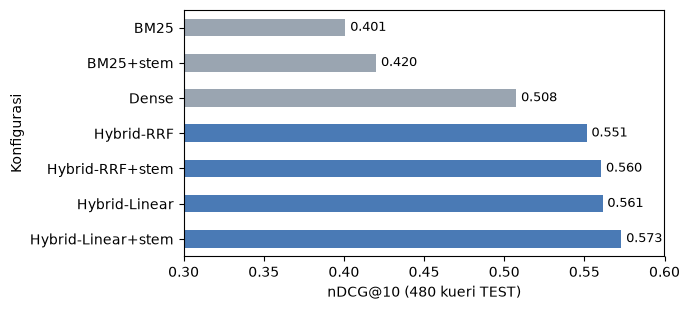

In [13]:
ax = tabel["nDCG@10"].plot.barh(figsize=(7, 3.2), color=["#9aa5b1"] * 3 + ["#4a7ab5"] * 4)
ax.invert_yaxis(); ax.set_xlabel("nDCG@10 (480 kueri TEST)"); ax.set_xlim(0.3, 0.6)
for i, v in enumerate(tabel["nDCG@10"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

## 6. Uji statistik (bootstrap, randomisasi, koreksi Holm)

In [14]:
a, b = per_kueri["Hybrid-Linear+stem"]["nDCG@10"].values, per_kueri["Dense"]["nDCG@10"].values
delta, lo, hi = paired_bootstrap_ci(a, b)
p = paired_randomization(a, b)
print(f"Hybrid-Linear+stem vs Dense: delta = {delta:+.4f}, IK 95% [{lo:.4f}, {hi:.4f}], p (sebelum Holm) = {p:.4f}")

Hybrid-Linear+stem vs Dense: delta = +0.0656, IK 95% [0.0459, 0.0856], p (sebelum Holm) = 0.0001


In [15]:
sig = pd.read_csv(OUT / "significance_test.csv")
sig[sig.metrik == "nDCG@10"][["A", "B", "delta(A-B)", "CI95_bawah", "CI95_atas", "p", "p_holm", "signifikan(0.05)"]].reset_index(drop=True)

,A,B,delta(A-B),CI95_bawah,CI95_atas,p,p_holm,signifikan(0.05)
0,Hybrid-RRF,BM25,0.1505,0.1289,0.1726,0.0001,0.0013,True
1,Hybrid-RRF,Dense,0.0439,0.0247,0.0640,0.0001,0.0013,True
2,Hybrid-Linear,BM25,0.1604,0.1380,0.1833,0.0001,0.0013,True
3,Hybrid-Linear,Dense,0.0538,0.0350,0.0733,0.0001,0.0013,True
4,Hybrid-RRF+stem,BM25+stem,0.1404,0.1188,0.1621,0.0001,0.0013,True
5,Hybrid-RRF+stem,Dense,0.0530,0.0343,0.0724,0.0001,0.0013,True
6,Hybrid-Linear+stem,BM25+stem,0.1529,0.1308,0.1751,0.0001,0.0013,True
7,Hybrid-Linear+stem,Dense,0.0656,0.0459,0.0856,0.0001,0.0013,True
8,Hybrid-Linear,Hybrid-RRF,0.0099,0.0016,0.0183,0.0171,0.0684,False
9,Hybrid-Linear+stem,Hybrid-RRF+stem,0.0126,0.0040,0.0213,0.0041,0.0205,True


## 7. Sensitivitas parameter fusi (kueri TUNE)

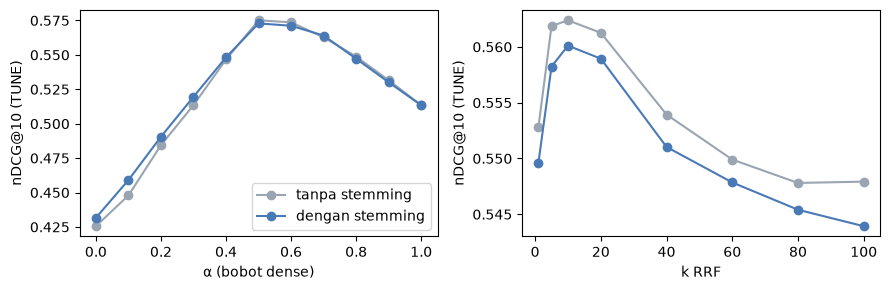

In [16]:
tun = pd.read_csv(OUT / "tuning.csv")
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for stem, warna in [(False, "#9aa5b1"), (True, "#4a7ab5")]:
    for i, (mode, label) in enumerate([("linear", "α (bobot dense)"), ("rrf", "k RRF")]):
        d = tun[(tun["mode"] == mode) & (tun.stem == stem)]
        ax[i].plot(d.value, d["nDCG@10_tune"], marker="o", color=warna, label="dengan stemming" if stem else "tanpa stemming")
        ax[i].set_xlabel(label); ax[i].set_ylabel("nDCG@10 (TUNE)")
ax[0].legend(); plt.tight_layout(); plt.show()

## 8. Kecepatan per kueri (20 kueri TEST)

In [17]:
import statistics
lat = {}
for nama, mode, stem, p in KONFIG:
    w = []
    for q in test[:20]:
        t = time.perf_counter(); searcher.search(queries[q], mode=mode, stem=stem, **p); w.append((time.perf_counter() - t) * 1000)
    lat[nama] = statistics.median(w)
pd.Series(lat, name="median (ms)").to_frame()

,median (ms)
BM25,8.5254
BM25+stem,8.9194
Dense,64.1215
Hybrid-RRF,73.5022
Hybrid-RRF+stem,64.5390
Hybrid-Linear,65.1936
Hybrid-Linear+stem,67.3942


## 9. Eksperimen fine-tuning E5 (hasil tersimpan)

In [18]:
zs = pd.read_csv(OUT / "results_test.csv", index_col=0)["nDCG@10"]
ft = pd.read_csv(OUT / "ft/results_test.csv", index_col=0)["nDCG@10"]
pd.DataFrame({"E5 asli": zs, "E5 fine-tuned": ft, "selisih": ft - zs}).loc[["Dense", "Hybrid-RRF+stem", "Hybrid-Linear+stem"]]

,E5 asli,E5 fine-tuned,selisih
Konfigurasi,,,
Dense,0.5075,0.4942,-0.0133
Hybrid-RRF+stem,0.5605,0.5367,-0.0238
Hybrid-Linear+stem,0.5731,0.5525,-0.0205
